In [ ]:
# JERICHON import bootstrap (shared resolver in src/project_paths.py)
from pathlib import Path
import os, sys

# Locate repository from the current working directory or its parents.
_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
for _base in list(_candidates):
    try:
        _candidates.extend(_child for _child in _base.iterdir() if _child.is_dir())
    except (OSError, PermissionError):
        pass
PROJECT_ROOT = next((p.resolve() for p in _candidates
                     if (p / "src" / "__init__.py").is_file()
                     and (p / "src" / "data" / "builders").is_dir()), None)
if PROJECT_ROOT is None:
    _env_root = os.environ.get("JERICHON_PROJECT_ROOT")
    if _env_root:
        _candidate = Path(_env_root).expanduser().resolve()
        if (_candidate / "src" / "__init__.py").is_file():
            PROJECT_ROOT = _candidate
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Не найден корень JERICHON. Откройте VS Code в папке репозитория "
        "или задайте JERICHON_PROJECT_ROOT.")
if str(PROJECT_ROOT) in sys.path:
    sys.path.remove(str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT))
from src.project_paths import bootstrap_project, find_project_root
PROJECT_ROOT = bootstrap_project(PROJECT_ROOT)


# JERICHON — Research 03: устойчивость рыночных режимов и адаптивная стратегия

**Задача:** не закрывать гипотезу режимов после одного неудачного holdout. Провести серию причинно корректных walk-forward экспериментов: разные представления состояния рынка, окна 5/10/20 минут, K-Means/GMM, K=2..5, глобальная модель против regime-specialists, несколько конфигураций CatBoost, и аудит торговых сделок.

**Важно:** этот notebook повторно строит локальную историю, Dollar Bars, 474 признака и Triple Barrier labels по существующему проектному pipeline. Он не меняет `backtest_engine.py`, не обращается к API и не переобучает/изменяет сохранённые модели.

**Протокол:** обучение кластеризатора, имputation, clipping, scaling, PCA и CatBoost выполняются только на train каждого fold. Train-события, чьи `t1` достигают validation начала, исключаются. Результаты всех fold считаются исследовательскими: после выбора гипотезы понадобится отдельный более поздний период для финальной проверки.

## 1. Подготовка данных

Ниже сохранена подготовительная часть текущего `JERICHON_mark_63.6.ipynb`: локальная история AlgoPack → Dollar Bars → 73 base + 401 Super Candle feature → аудит временной доступности → CUSUM + Triple Barrier → бинарные метки `DOWN=0`, `UP=1`, `TIME` исключается.

Не запускайте старый раздел с фиксированным 75/25 split: после построения `X_all`, `y_binary`, `labeled`, `bars` и `FINAL_DATASET` дальнейшие ячейки этого ноутбука строят собственные purged walk-forward folds.

In [22]:
# 0. CONFIG + IMPORTS
from pathlib import Path
import sys, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplcyberpunk
plt.style.use('cyberpunk')
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix)

TICKER = "GAZP"                  # поменяй тикер при необходимости
DOLLAR_THRESHOLD = 10_000_000   # порог из reference notebook jerichon_mark_63(3)
MSK = "Europe/Moscow"
# Historical labels: CUSUM events + Triple Barrier (not fixed-horizon return labels).
CUSUM_THRESHOLD = 0.001
PT_SL = (2.4, 1.5)              # (take-profit multiplier, stop-loss multiplier); intentionally asymmetric
VERTICAL_HORIZON = 50           # vertical barrier in Dollar Bars
TARGET_WINDOW = 55              # volatility estimate window for Triple Barrier
EXPECTED_FEATURES = 474

# Автоматически ищем корень репозитория JERICHON, не фиксируем путь конкретного пользователя.
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    raise FileNotFoundError(
        "Не найден корень JERICHON. Открой notebook из папки репозитория "
        "или укажи PROJECT_ROOT вручную."
    )

ROOT = PROJECT_ROOT / "data"
if str(ROOT.parent) not in sys.path:
    sys.path.insert(0, str(ROOT.parent))
HISTORY_ROOT = ROOT / "for_ml" / "storage" / "history"

from src.data.builders.dollar_bars import InformationDrivenBars
from src.data.builders.micro_features import MicroFeatures
from src.data.builders.build_features import FeatureBuilder
from src.data.builders import jerichon_feature_pipeline as jfp
from src.backtesting.backtest_engine import (backtest_saved_catboost, BacktestConfig,)

print("Ticker       :", TICKER)
print("Pipeline     :", Path(inspect.getfile(jfp)).resolve())
print("Pipeline API :", [n for n in ("build_feature_dataset", "build_dollar_bars_from_trades", "_base", "_build_sc_features", "_choose_availability", "_attach_source") if hasattr(jfp, n)])

Ticker       : GAZP
Pipeline     : C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Pipeline API : ['build_feature_dataset', 'build_dollar_bars_from_trades', '_base', '_build_sc_features', '_choose_availability', '_attach_source']


## 1. Загрузка локальной истории

Формат путей сохранён **как в `jerichon_mark_63(3).ipynb`**:

- `data/for_ml/storage/history/realtime/{TICKER}/{YYYY-MM-DD}/trades.parquet`
- `data/for_ml/storage/history/supercandles/{TICKER}/{YYYY-MM-DD}/{tradestats,obstats,orderstats}.parquet`

Файлы только читаются. Если какой-то источник отсутствует, notebook покажет это явно.

In [23]:
def available_dates(history_root, ticker):
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists():
            dates.update(x.name for x in p.iterdir() if x.is_dir())
    return sorted(d for d in dates if len(d) == 10 and d[4] == "-" and d[7] == "-")

def load_local_history(history_root, ticker):
    keys = ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")
    frames = {k: [] for k in keys}
    dates = available_dates(history_root, ticker)

    if not dates:
        raise FileNotFoundError(f"Для {ticker} не найдены сохранённые даты в {history_root}")

    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            p = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING: не удалось прочитать {p}: {e}")

        for key in ("tradestats", "obstats", "orderstats"):
            p = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING: не удалось прочитать {p}: {e}")

    out = {k: (pd.concat(v, ignore_index=True) if v else pd.DataFrame()) for k, v in frames.items()}
    print(f"Saved dates discovered: {len(dates)}")
    print(f"Date range            : {dates[0]} → {dates[-1]}")
    print("\\nLocal rows:")
    display(pd.DataFrame({"source": list(out), "rows": [len(out[k]) for k in out]}))
    missing = [s for s in ("trades", "tradestats", "obstats", "orderstats") if out[s].empty]
    if missing:
        raise RuntimeError(f"Не хватает локальных источников: {missing}. API-запрос не будет выполняться.")
    return out, dates

data, SAVED_DATES = load_local_history(HISTORY_ROOT, TICKER)

Saved dates discovered: 12
Date range            : 2026-09-24 → 2026-10-13
\nLocal rows:


,source,rows
0,candles,10509
1,trades,991251
2,orderbook,240
3,tradestats,2112
4,obstats,2052
5,orderstats,2124


## 2. Построение Dollar Bars и 474 признаков

Используем подготовленный модуль `jerichon_feature_pipeline.py`, а не копируем его инженерный код в notebook. Важно: **не вызываем** публичный `build_feature_dataset()`, если он сам создаёт `AlgoPackProvider`; вместо этого вызываем локальные функции модуля над уже прочитанными DataFrame.

Если локальная версия модуля не содержит ожидаемые helper-функции, выполнение остановится с понятной ошибкой, а не отправит запрос в API.

In [24]:
# Сначала проверяем интерфейс установленного файла — никаких сетевых вызовов здесь нет.
required_helpers = (
    "_trades_for_bars",
    "build_dollar_bars_from_trades",
    "_base",
    "_build_sc_features",
    "_choose_availability",
    "_attach_source",
)
missing_helpers = [name for name in required_helpers if not hasattr(jfp, name)]
if missing_helpers:
    raise RuntimeError(
        "В установленном jerichon_feature_pipeline.py не найдены helper-функции: "
        f"{missing_helpers}. Проверь, что в проекте стоит актуальная версия pipeline. "
        "Этот notebook намеренно не переключается на API."
    )

print("Helper signatures:")
for name in required_helpers:
    print(f"  {name}{inspect.signature(getattr(jfp, name))}")

Helper signatures:
  _trades_for_bars(trades)
  build_dollar_bars_from_trades(trades, threshold=13000000)
  _base(bars)
  _build_sc_features(raw_sources, bars_for_features)
  _choose_availability(df, source_name)
  _attach_source(bars, feature_frame, raw_source, source)


In [25]:
# Dollar Bars: используем тот же денежный объём VALUE / PRICE, что и в reference.
bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=DOLLAR_THRESHOLD)
if bars is None or bars.empty:
    raise RuntimeError("Dollar Bar builder вернул пустой результат.")

# Унифицируем имя времени для последующих causal joins.
if "bar_ts" not in bars.columns:
    if "close_time" not in bars.columns:
        raise RuntimeError(f"В bars нет bar_ts/close_time. Колонки: {list(bars.columns)}")
    bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
else:
    bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)

bars = (bars.dropna(subset=["bar_ts"])
             .sort_values("bar_ts")
             .drop_duplicates("bar_ts", keep="last")
             .reset_index(drop=True))

print("Dollar Bars:", len(bars))
print("Period:", bars["bar_ts"].min(), "→", bars["bar_ts"].max())
display(bars.head(3))

Dollar Bars: 6787
Period: 2026-09-24 03:59:40+00:00 → 2026-10-13 18:32:20+00:00


,open,high,low,close,volume,value,count,open_time,close_time,bar_ts
0,102.70,102.7,102.7,102.70,98230.0,10088221.0,108,2026-09-24 03:59:40+00:00,2026-09-24 03:59:40+00:00,2026-09-24 03:59:40+00:00
1,102.70,102.8,102.7,102.79,103150.0,10598897.9,285,2026-09-24 03:59:40+00:00,2026-09-24 04:00:02+00:00,2026-09-24 04:00:02+00:00
2,102.79,102.8,102.7,102.71,98480.0,10116145.1,87,2026-09-24 04:00:02+00:00,2026-09-24 04:00:21+00:00,2026-09-24 04:00:21+00:00


In [26]:
# Base 73 + Super Candle 401. Работаем через helper-функции pipeline.
base_raw = jfp._base(bars.copy())
if isinstance(base_raw, tuple):
    # Поддержка версий helper, возвращающих (features, metadata).
    base_raw = base_raw[0]
if not isinstance(base_raw, pd.DataFrame):
    raise TypeError(f"_base должен вернуть DataFrame, получено: {type(base_raw)}")

# Приводим base frame к контракту bar_ts + 73 числовых признака.
if "bar_ts" not in base_raw.columns:
    if "close_time" in base_raw.columns:
        base_raw = base_raw.rename(columns={"close_time": "bar_ts"})
    elif isinstance(base_raw.index, pd.DatetimeIndex):
        base_raw = base_raw.reset_index().rename(columns={base_raw.index.name or "index": "bar_ts"})
    elif "ts" in base_raw.columns:
        base_raw = base_raw.rename(columns={"ts": "bar_ts"})
    else:
        raise RuntimeError(f"Не найден временной ключ в _base output. Колонки: {list(base_raw.columns)[:25]}")

base_raw["bar_ts"] = pd.to_datetime(base_raw["bar_ts"], errors="coerce", utc=True)
base_raw = base_raw.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)

# _build_sc_features может возвращать feature_frames либо (feature_frames, groups).
# Адаптируем Dollar Bars к формату, ожидаемому pipeline.
bars_for_sc = bars.copy()

# В pipeline ожидаются ts и CLOSE.
if "ts" not in bars_for_sc.columns:
    if "bar_ts" in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["bar_ts"]
    elif "close_time" in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["close_time"]
    else:
        raise KeyError("В bars отсутствует временная колонка ts/bar_ts/close_time")

if "CLOSE" not in bars_for_sc.columns:
    if "close" in bars_for_sc.columns:
        bars_for_sc["CLOSE"] = bars_for_sc["close"]
    else:
        raise KeyError("В bars отсутствует цена закрытия CLOSE/close")

bars_for_sc["ts"] = pd.to_datetime(bars_for_sc["ts"], errors="coerce", utc=True)

bars_for_sc = (
    bars_for_sc.dropna(subset=["ts"])
    .sort_values("ts")
    .reset_index(drop=True))

sc_result = jfp._build_sc_features(data, bars_for_sc)

if isinstance(sc_result, tuple):
    feature_frames = sc_result[0]
    feature_groups = sc_result[1] if len(sc_result) > 1 else {}
else:
    feature_frames = sc_result
    feature_groups = {}

if not isinstance(feature_frames, dict):
    raise TypeError("_build_sc_features должен возвращать dict feature frames.")

print("Base output shape:", base_raw.shape)
print("Super Candle feature groups:", list(feature_frames))

Base output shape: (6787, 74)
Super Candle feature groups: ['tradestats', 'orderstats', 'obstats']


C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

In [27]:
# Availability validation and causal joins, source by source.
# Helpers' outputs are inspected to support the current prepared module contract.
validated = {}
availability_diagnostics = []

for source in ("tradestats", "obstats", "orderstats"):
    if data[source].empty:
        raise RuntimeError(f"Локальный источник {source} пуст.")

    result = jfp._choose_availability(data[source].copy(), source)
    if isinstance(result, tuple):
        validated[source] = result[0]
        if len(result) > 1 and isinstance(result[1], pd.DataFrame):
            availability_diagnostics.append(result[1])
    else:
        validated[source] = result

print("Validated sources:")
for source, frame in validated.items():
    print(f"  {source:12s}: {len(frame):,} rows, columns={len(frame.columns)}")

if availability_diagnostics:
    display(pd.concat(availability_diagnostics, ignore_index=True))

Validated sources:
  tradestats  : 2,112 rows, columns=2
  obstats     : 2,052 rows, columns=2
  orderstats  : 2,124 rows, columns=2


In [28]:
# Normalize the bars frame for the pipeline's attach helper.
bar_frame = bars.copy()
if "bar_ts" not in bar_frame.columns:
    raise RuntimeError("bar_ts missing from Dollar Bars.")

# Resolve each raw source to the corresponding feature frame by name.
def resolve_feature_frame(source, frames):
    if source in frames:
        return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches) == 1:
        return frames[matches[0]]
    raise RuntimeError(f"Не удалось однозначно сопоставить {source} с feature frame. Доступны: {list(frames)}")

causal = bar_frame.copy()
for source in ("tradestats", "obstats", "orderstats"):
    feature_frame = resolve_feature_frame(source, feature_frames)
    
    # ИСПРАВЛЕНО: правильный порядок аргументов + исходные данные вместо validated
    attached = jfp._attach_source(causal, feature_frame, data[source], source)
    
    # Поддержка helper, возвращающего либо изменённый frame, либо None in-place.
    if isinstance(attached, pd.DataFrame):
        causal = attached
    print(f"{source:12s} attached → {causal.shape}")

# Добавляем base features по точному bar_ts.
base_cols = [c for c in base_raw.columns if c != "bar_ts" and pd.api.types.is_numeric_dtype(base_raw[c])]
if len(base_cols) != 73:
    raise RuntimeError(f"Ожидалось 73 base features, найдено {len(base_cols)}.")

base_join = base_raw[["bar_ts"] + base_cols].copy()
base_join = base_join.rename(columns={c: f"base__{c}" for c in base_cols})
base_cols = [c for c in base_join.columns if c.startswith("base__")]

if "bar_ts" not in causal.columns:
    raise RuntimeError(f"После causal join нет bar_ts. Колонки: {list(causal.columns)[:30]}")

causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
base_join["bar_ts"] = pd.to_datetime(base_join["bar_ts"], errors="coerce", utc=True)
causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

# Identify features and provenance without admitting timestamps into X.
time_cols = {"bar_ts", "bar_ts_utc", "ts", "ts_utc", "close_time"}
provenance_cols = [
    c for c in causal.columns
    if c.endswith("__event_ts") or c.endswith("__available_at")
]
sc_prefixes = ("tradestats__", "obstats__", "orderstats__")
sc_feature_cols = [
    c for c in causal.columns
    if c.startswith(sc_prefixes)
    and c not in provenance_cols
    and pd.api.types.is_numeric_dtype(causal[c])
]
# Не включаем сырые OHLCV/служебные колонки из bars: только канонические 73 + 401.
feature_cols = base_cols + sc_feature_cols

if len(feature_cols) != EXPECTED_FEATURES:
    raise RuntimeError(
        f"Feature inventory mismatch: {len(feature_cols)} numeric ML features, expected {EXPECTED_FEATURES}. "
        "Не продолжаем обучение на непроверенной матрице."
    )

if len(feature_cols) != len(set(feature_cols)):
    raise RuntimeError("Есть дублирующиеся имена признаков.")

FINAL_DATASET = causal[["bar_ts"] + feature_cols + provenance_cols].copy()
FINAL_DATASET = FINAL_DATASET.sort_values("bar_ts").reset_index(drop=True)
X_raw = FINAL_DATASET[feature_cols].copy()

print("FINAL_DATASET:", FINAL_DATASET.shape)
print("Rows:", len(FINAL_DATASET))
print("ML features:", len(feature_cols))
print("Provenance columns:", len(provenance_cols))

tradestats   attached → (6787, 106)
obstats      attached → (6787, 244)
orderstats   attached → (6787, 417)
FINAL_DATASET: (6787, 481)
Rows: 6787
ML features: 474
Provenance columns: 6


## 3. Temporal audit

Проверяем `available_at <= bar_ts` и `event_ts <= bar_ts` для каждого источника. Признаки из будущего — блокирующая ошибка. Дубликаты/пропуски/бесконечности дальше рассматриваются отдельно.

In [29]:
temporal_rows = []
for source in ("tradestats", "obstats", "orderstats"):
    av_col = f"{source}__available_at"
    ev_col = f"{source}__event_ts"
    if av_col not in FINAL_DATASET.columns or ev_col not in FINAL_DATASET.columns:
        raise RuntimeError(f"Нет provenance для {source}: ожидались {av_col}, {ev_col}")

    av = pd.to_datetime(FINAL_DATASET[av_col], errors="coerce", utc=True)
    ev = pd.to_datetime(FINAL_DATASET[ev_col], errors="coerce", utc=True)
    bar_ts = pd.to_datetime(FINAL_DATASET["bar_ts"], errors="coerce", utc=True)

    bad_av = av.notna() & (av > bar_ts)
    bad_ev = ev.notna() & (ev > bar_ts)
    temporal_rows.append({
        "source": source,
        "bars": len(FINAL_DATASET),
        "availability_future_violations": int(bad_av.sum()),
        "event_future_violations": int(bad_ev.sum()),
        "availability_missing_pct": round(float(av.isna().mean() * 100), 3),
        "event_missing_pct": round(float(ev.isna().mean() * 100), 3),
    })

temporal_audit = pd.DataFrame(temporal_rows)
display(temporal_audit)

if temporal_audit[["availability_future_violations", "event_future_violations"]].to_numpy().sum() != 0:
    raise RuntimeError("TEMPORAL AUDIT FAILED: обнаружен look-ahead по provenance.")
print("TEMPORAL AUDIT: PASS")

,source,bars,availability_future_violations,event_future_violations,availability_missing_pct,event_missing_pct
0,tradestats,6787,0,0,0.029,0.029
1,obstats,6787,0,0,0.280,0.280
2,orderstats,6787,0,0,0.000,0.000


TEMPORAL AUDIT: PASS


## 4. Проверка качества признаков

Нулевые значения не удаляем автоматически. Важные показатели:
- `NaN` и `±inf` по каждому признаку;
- доля нулей (диагностика, не критерий удаления);
- константные признаки;
- полностью пустые признаки;
- дублирующиеся строки и timestamps.

Исходный `FINAL_DATASET` не перезаписывается. Для модели создаётся отдельная копия, в которой бесконечности переводятся в `NaN`; далее imputer обучается только на train.

In [30]:
X_num = X_raw.apply(pd.to_numeric, errors="coerce")
arr = X_num.to_numpy(dtype="float64", copy=True)
finite_mask = np.isfinite(arr)

quality = pd.DataFrame(index=X_num.columns)
quality["missing_pct"] = X_num.isna().mean() * 100
quality["positive_inf"] = np.isposinf(arr).sum(axis=0)
quality["negative_inf"] = np.isneginf(arr).sum(axis=0)
quality["zero_pct"] = (X_num.eq(0).mean() * 100)
quality["unique_values"] = X_num.nunique(dropna=True)
quality["all_missing"] = X_num.isna().all()
quality["constant_or_single_value"] = quality["unique_values"] <= 1
quality["non_finite_total"] = quality["positive_inf"] + quality["negative_inf"]

print("Rows:", len(X_num), "| features:", X_num.shape[1])
print("NaN cells:", int(X_num.isna().sum().sum()))
print("+inf cells:", int(np.isposinf(arr).sum()))
print("-inf cells:", int(np.isneginf(arr).sum()))
print("Zero cells (% of all feature cells):", round(float(X_num.eq(0).to_numpy().mean() * 100), 2))
print("Duplicate bar_ts:", int(FINAL_DATASET["bar_ts"].duplicated().sum()))
print("Duplicate feature rows:", int(X_num.duplicated().sum()))

print("\\nWorst missingness:")
display(quality.sort_values(["missing_pct", "non_finite_total"], ascending=False).head(30))

print("\\nFeatures with infinities:")
display(quality.loc[quality["non_finite_total"] > 0].sort_values("non_finite_total", ascending=False))

print("\\nConstant / all-missing features:")
display(quality.loc[quality["constant_or_single_value"] | quality["all_missing"]])

Rows: 6787 | features: 474
NaN cells: 10563
+inf cells: 0
-inf cells: 0
Zero cells (% of all feature cells): 0.72
Duplicate bar_ts: 0
Duplicate feature rows: 0
\nWorst missingness:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total
tradestats__ts_vwap_b_s_bps_ret,9.606601,0,0,0.442022,1455,False,False,0
tradestats__ts_flow_x_return_ret,5.466333,0,0,0.044202,1632,False,False,0
obstats__ob_val_imb_bbo_vs_deep_ret,1.635480,0,0,0.810373,1385,False,False,0
obstats__ob_vol_imb_bbo_vs_deep_ret,1.414469,0,0,1.620746,1396,False,False,0
orderstats__os_put_vwap_b_s_bps_ret,0.766171,0,0,0.000000,1847,False,False,0
tradestats__ts_trade_imbalance_ret,0.633564,0,0,0.000000,1830,False,False,0
obstats__ob_total_volume_z3,0.574628,0,0,0.000000,1808,False,False,0
obstats__ob_total_volume_ma3,0.574628,0,0,0.000000,1808,False,False,0
obstats__ob_total_volume_z6,0.574628,0,0,0.000000,1808,False,False,0
obstats__ob_total_volume_ma6,0.574628,0,0,0.000000,1808,False,False,0


\nFeatures with infinities:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total


\nConstant / all-missing features:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total


In [31]:
# Separate ML copy: keep source dataset unchanged.
X_model = X_num.replace([np.inf, -np.inf], np.nan).copy()

# Remove only features that cannot carry information at all (all missing or constant).
drop_features = quality.index[quality["all_missing"] | quality["constant_or_single_value"]].tolist()
if drop_features:
    print("Removing non-informative columns from model copy:", len(drop_features))
    print(drop_features[:30])
    X_model = X_model.drop(columns=drop_features)

print("X_model shape:", X_model.shape)
print("Remaining NaN cells (to be handled by train-only imputer):", int(X_model.isna().sum().sum()))

# Optional strict stop for pathological data; does not delete rows.
if X_model.shape[1] == 0:
    raise RuntimeError("После удаления пустых/константных признаков не осталось признаков.")

X_model shape: (6787, 474)
Remaining NaN cells (to be handled by train-only imputer): 10563


## 5. CUSUM + Triple Barrier: бинарная цель UP/DOWN

Triple Barrier по-прежнему строит три исходные метки, чтобы диагностировать распределение событий:
- `+1` — первым достигнут верхний барьер (`UP`);
- `-1` — первым достигнут нижний барьер (`DOWN`);
- `0` — до вертикального барьера не достигнут ни один горизонтальный барьер (`TIME`).

**В модель `TIME` не попадает вообще.** После визуализации распределения остаются только события `UP` и `DOWN`, а целевая переменная кодируется как `DOWN=0`, `UP=1`. Train/holdout делятся хронологически, пересекающие границу исходы purged.

CUSUM + TRIPLE BARRIER
CUSUM threshold : 0.001
PT_SL           : (2.4, 1.5) (TP multiplier, SL multiplier)
Vertical horizon: 50 Dollar Bars
Target window   : 55
CUSUM events    : 2,187
Triple Barrier events: 2,186
Raw labels: -1=DOWN, 0=TIME, +1=UP
  DOWN :   1,338 ( 61.21%)
  TIME :      26 (  1.19%)
  UP   :     822 ( 37.60%)


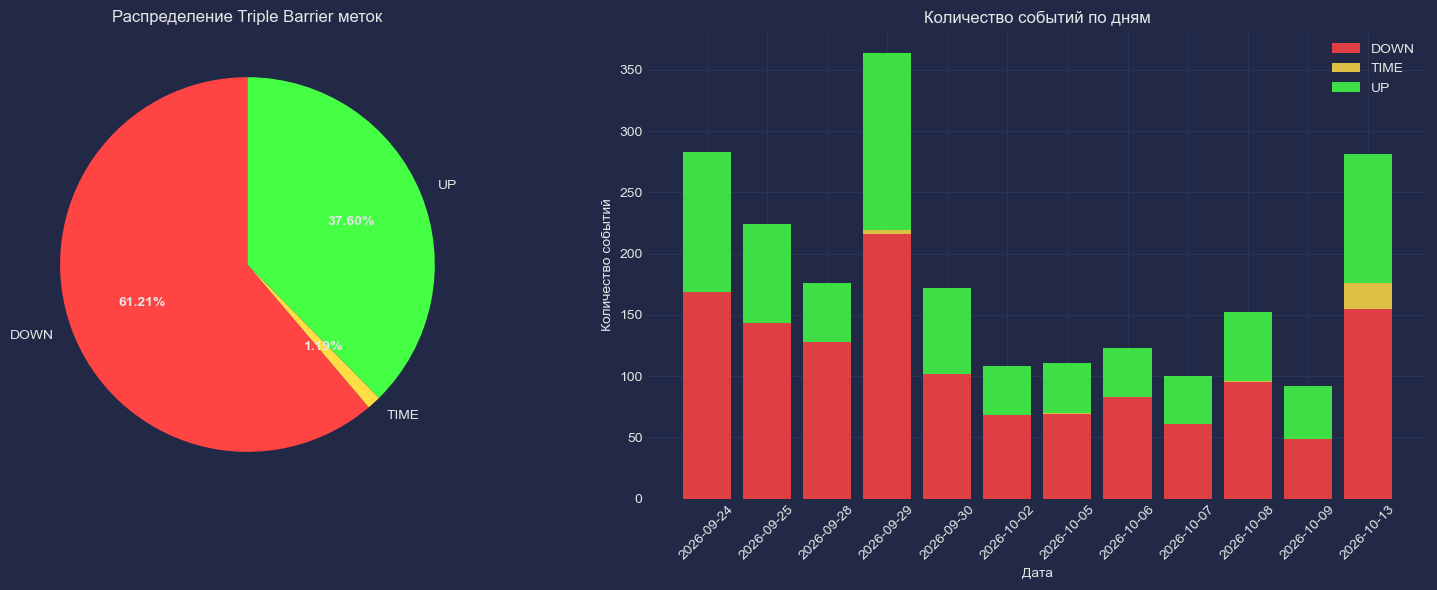


Aligned events before excluding TIME: 2,186
label
-1    1338
 0      26
 1     822
Name: count, dtype: int64


In [32]:
# =============================================================================
# LABELS: CUSUM → TRIPLE BARRIER → EVENT-ALIGNED X/y → BINARY TARGET
# =============================================================================
from src.data.labeling.cusum import cusum_filter
from src.data.labeling.triple_barrier import triple_barrier_labeling

# Use exactly the Dollar Bars that produced FINAL_DATASET.
bars_for_labeling = bars.copy()
if "bar_ts" not in bars_for_labeling.columns:
    raise RuntimeError(f"В bars отсутствует bar_ts. Колонки: {list(bars_for_labeling.columns)}")

rename_map = {
    "open": "OPEN", "high": "HIGH", "low": "LOW", "close": "CLOSE",
    "OPEN": "OPEN", "HIGH": "HIGH", "LOW": "LOW", "CLOSE": "CLOSE",
}
bars_for_labeling = bars_for_labeling.rename(columns=rename_map)
required_ohlc = ["HIGH", "LOW", "CLOSE"]
missing_ohlc = [c for c in required_ohlc if c not in bars_for_labeling.columns]
if missing_ohlc:
    raise RuntimeError(f"Для Triple Barrier не хватает OHLC-колонок: {missing_ohlc}")

bars_for_labeling["bar_ts"] = pd.to_datetime(
    bars_for_labeling["bar_ts"], errors="coerce", utc=True
)
bars_for_labeling = (
    bars_for_labeling.dropna(subset=["bar_ts"] + required_ohlc)
    .sort_values("bar_ts")
    .drop_duplicates("bar_ts", keep="last")
    .set_index("bar_ts")
)
bars_for_labeling.index.name = "bar_ts"

events_idx = cusum_filter(
    bars_for_labeling["CLOSE"].astype(float),
    threshold=CUSUM_THRESHOLD,
)
events_idx = pd.DatetimeIndex(events_idx)
events_idx = events_idx[events_idx.isin(bars_for_labeling.index)]
events_idx = events_idx.drop_duplicates().sort_values()

print("=" * 80)
print("CUSUM + TRIPLE BARRIER")
print("=" * 80)
print(f"CUSUM threshold : {CUSUM_THRESHOLD}")
print(f"PT_SL           : {PT_SL} (TP multiplier, SL multiplier)")
print(f"Vertical horizon: {VERTICAL_HORIZON} Dollar Bars")
print(f"Target window   : {TARGET_WINDOW}")
print(f"CUSUM events    : {len(events_idx):,}")
if len(events_idx) == 0:
    raise RuntimeError("CUSUM не нашёл событий. Проверь CUSUM_THRESHOLD и входные бары.")

labeled_all = triple_barrier_labeling(
    bars=bars_for_labeling,
    events=events_idx,
    pt_sl=PT_SL,
    vertical_barrier=VERTICAL_HORIZON,
    target_window=TARGET_WINDOW,
    target_method="ewm",
)
if labeled_all is None or labeled_all.empty:
    raise RuntimeError("Triple Barrier вернул пустую таблицу меток.")
if not {"label", "t1"}.issubset(labeled_all.columns):
    raise RuntimeError(
        "Ожидались колонки label и t1; получены: "
        f"{list(labeled_all.columns)}"
    )

labeled_all.index = pd.to_datetime(labeled_all.index, errors="coerce", utc=True)
labeled_all = labeled_all[~labeled_all.index.isna()].sort_index()
labeled_all = labeled_all[labeled_all["label"].isin([-1, 0, 1])].copy()
labeled_all["label"] = labeled_all["label"].astype(int)
labeled_all["t1"] = pd.to_datetime(labeled_all["t1"], errors="coerce", utc=True)

print(f"Triple Barrier events: {len(labeled_all):,}")
print("Raw labels: -1=DOWN, 0=TIME, +1=UP")
label_counts = labeled_all["label"].value_counts().reindex([-1, 0, 1], fill_value=0)
for value, name in [(-1, "DOWN"), (0, "TIME"), (1, "UP")]:
    count = int(label_counts.loc[value])
    pct = 100 * count / len(labeled_all) if len(labeled_all) else 0
    print(f"  {name:5s}: {count:7,d} ({pct:6.2f}%)")

# Visual diagnostics include TIME so we can see how often the vertical barrier wins.
label_names = {-1: "DOWN", 0: "TIME", 1: "UP"}
label_colors = {-1: "#ff4444", 0: "#ffdd44", 1: "#44ff44"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_counts = [int(label_counts.loc[v]) for v in (-1, 0, 1)]
if sum(plot_counts):
    _, _, autotexts = axes[0].pie(
        plot_counts,
        labels=[label_names[v] for v in (-1, 0, 1)],
        colors=[label_colors[v] for v in (-1, 0, 1)],
        autopct="%1.2f%%",
        startangle=90,
    )
    for t in autotexts:
        t.set_fontsize(10)
        t.set_fontweight("bold")
axes[0].set_title("Распределение Triple Barrier меток")

plot_labels = pd.DataFrame({
    "day": pd.DatetimeIndex(labeled_all.index).date,
    "label": labeled_all["label"].to_numpy(),
})
daily_counts = (
    plot_labels.groupby(["day", "label"]).size()
    .unstack(fill_value=0)
    .reindex(columns=[-1, 0, 1], fill_value=0)
    .sort_index()
)
bottom = np.zeros(len(daily_counts), dtype=float)
for cls in (-1, 0, 1):
    vals = daily_counts[cls].to_numpy()
    axes[1].bar(
        daily_counts.index.astype(str), vals, bottom=bottom,
        label=label_names[cls], color=label_colors[cls], alpha=0.85,
    )
    bottom += vals
axes[1].set_title("Количество событий по дням")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Количество событий")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

# Event-aligned X/y. One concat avoids pandas' highly-fragmented DataFrame warning.
if len(FINAL_DATASET) != len(X_model):
    raise RuntimeError(
        f"FINAL_DATASET и X_model имеют разную длину: {len(FINAL_DATASET)} vs {len(X_model)}"
    )
model_feature_cols = list(X_model.columns)
feature_table = pd.concat(
    [FINAL_DATASET[["bar_ts"]].reset_index(drop=True),
     X_model.reset_index(drop=True)],
    axis=1,
)
feature_table["bar_ts"] = pd.to_datetime(feature_table["bar_ts"], errors="coerce", utc=True)
feature_table = feature_table.dropna(subset=["bar_ts"]).set_index("bar_ts").sort_index()

X_all_raw = feature_table.reindex(labeled_all.index)[model_feature_cols].copy()
y_all_raw = labeled_all["label"].reindex(X_all_raw.index)
aligned = y_all_raw.notna() & X_all_raw.index.notna()
X_all_raw = X_all_raw.loc[aligned].copy()
y_all_raw = y_all_raw.loc[aligned].astype(int)
labeled_all = labeled_all.reindex(X_all_raw.index)

if not X_all_raw.index.equals(y_all_raw.index):
    raise RuntimeError("X/y event indices are not aligned.")
if X_all_raw.index.has_duplicates:
    raise RuntimeError("Duplicate event timestamps after feature/label alignment.")

print(f"\nAligned events before excluding TIME: {len(X_all_raw):,}")
print(y_all_raw.value_counts().reindex([-1, 0, 1], fill_value=0))

# TIME is not a prediction target. Keep only events where TP or SL won.
directional_mask = y_all_raw.isin([-1, 1])
X_all = X_all_raw.loc[directional_mask].copy()
y_all = y_all_raw.loc[directional_mask].copy()
labeled = labeled_all.reindex(X_all.index).copy()

if set(y_all.unique()) != {-1, 1}:
    raise RuntimeError(f"Ожидались оба directional класса -1/+1; получены {sorted(y_all.unique())}")

# Binary target for CatBoost: DOWN=0, UP=1.
label_map = {-1: 0, 1: 1}
y_binary = y_all.map(label_map).astype(int)

# Chronological 75/25 holdout split. Purge training outcomes reaching holdout start.
if len(X_all) < 100:
    raise RuntimeError(f"Слишком мало directional событий: {len(X_all)}")
split_idx = int(len(X_all) * 0.75)
if split_idx <= 0 or split_idx >= len(X_all):
    raise RuntimeError("Невозможно построить chronological split.")

HOLDOUT_START = X_all.index[split_idx]
train_candidate_index = X_all.index[:split_idx]
test_index = X_all.index[split_idx:]
train_end_times = labeled.reindex(train_candidate_index)["t1"]
train_keep = train_end_times.notna() & (train_end_times < HOLDOUT_START)
train_index = train_candidate_index[train_keep.to_numpy()]


## 2. Контракт данных и причинные walk-forward folds

Сначала проверяем индексы и разметку. Используем три expanding-window fold: обучение на первых 50/65/80% событий, проверка на следующих 15/15/20%. Для каждого fold обучающие события с `t1 >= validation_start` удаляются, а validation-события с `t1` за пределами собственного validation-интервала не используются в метриках/торговле.

In [33]:
# 2. DATA CONTRACT + PURGED WALK-FORWARD FOLDS
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    log_loss, brier_score_loss, silhouette_score
)
from catboost import CatBoostClassifier
from src.backtesting.backtest_engine import backtest, BacktestConfig
from pathlib import Path
import inspect, warnings, time, json, math

SEED = 63
INITIAL_CAPITAL = 100_000.0
COMMISSION = 0.0006
SLIPPAGE = 0.0001
ENTRY_CUTOFF_HOUR = 22
FORCED_CLOSE_HOUR = 23
SESSION_TIMEZONE = "Europe/Moscow"
MIN_REGIME_TRAIN_EVENTS = 100
PCA_COMPONENTS = 20
CLUSTER_K_VALUES = (2, 3, 4, 5)
WINDOWS = ("5min", "10min", "20min")

required_objects = ["bars", "X_model", "FINAL_DATASET", "X_all", "y_binary", "labeled"]
missing_objects = [x for x in required_objects if x not in globals()]
if missing_objects:
    raise RuntimeError(f"Не хватает объектов из подготовительных ячеек: {missing_objects}")

X_all = X_all.copy()
X_all.index = pd.to_datetime(X_all.index, errors="coerce", utc=True)
y_binary = y_binary.copy()
y_binary.index = pd.to_datetime(y_binary.index, errors="coerce", utc=True)
labeled = labeled.copy()
labeled.index = pd.to_datetime(labeled.index, errors="coerce", utc=True)
labeled["t1"] = pd.to_datetime(labeled["t1"], errors="coerce", utc=True)
labeled = labeled.loc[~labeled.index.isna()].sort_index()
X_all = X_all.loc[~X_all.index.isna()].sort_index()
y_binary = y_binary.loc[~y_binary.index.isna()].sort_index()

common = X_all.index.intersection(y_binary.index).intersection(labeled.index)
X_all, y_binary, labeled = X_all.loc[common], y_binary.loc[common], labeled.loc[common]
if X_all.index.has_duplicates or not X_all.index.equals(y_binary.index) or not X_all.index.equals(labeled.index):
    raise RuntimeError("X/y/labels имеют дубли или несовпадающие индексы.")
if set(y_binary.unique()) != {0, 1}:
    raise RuntimeError(f"Ожидались классы DOWN=0, UP=1; получены {sorted(y_binary.unique())}")
if not {"upper", "lower", "t1"}.issubset(labeled.columns):
    raise RuntimeError("В labeled нужны upper/lower/t1 для существующего backtest_engine.")

bars = bars.copy()
if "bar_ts" not in bars.columns:
    raise RuntimeError("В bars отсутствует bar_ts.")
bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)
bars = bars.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts").reset_index(drop=True)

n = len(X_all)
fold_specs = [
    ("WF1", 0.50, 0.65),
    ("WF2", 0.65, 0.80),
    ("WF3", 0.80, 1.00),
]
folds = []
for name, train_frac, val_end_frac in fold_specs:
    train_end_pos = int(n * train_frac)
    val_end_pos = min(n, int(n * val_end_frac))
    train_candidates = X_all.index[:train_end_pos]
    val_idx = X_all.index[train_end_pos:val_end_pos]
    if len(val_idx) == 0:
        continue
    val_start = val_idx[0]
    # For the final fold, allow event outcomes to finish on the available bar history,
    # not merely before the timestamp of the last CUSUM event.
    val_end = (X_all.index[val_end_pos] if val_end_pos < n
               else pd.to_datetime(bars["bar_ts"], utc=True).max() + pd.Timedelta(nanoseconds=1))
    t1_train = labeled.reindex(train_candidates)["t1"]
    train_idx = train_candidates[(t1_train.notna() & (t1_train < val_start)).to_numpy()]
    # Do not score validation events whose outcomes extend past the validation interval.
    val_t1 = labeled.reindex(val_idx)["t1"]
    val_idx = val_idx[(val_t1.notna() & (val_t1 < val_end)).to_numpy()]
    if len(train_idx) < 200 or len(val_idx) < 50:
        raise RuntimeError(f"{name}: слишком мало событий после purge: train={len(train_idx)}, val={len(val_idx)}")
    folds.append({"name": name, "train_idx": train_idx, "val_idx": val_idx,
                  "val_start": val_start, "val_end": val_end})
    print(f"{name}: train={len(train_idx):,}; validation={len(val_idx):,}; "
          f"train_end={train_idx[-1]}; val={val_idx[0]} → {val_idx[-1]}")

print("Events:", len(X_all), "| full features:", X_all.shape[1])
print("Backtest API:", inspect.signature(backtest))
print("BacktestConfig:", list(BacktestConfig.__dataclass_fields__))


WF1: train=1,060; validation=311; train_end=2026-09-30 05:17:46+00:00; val=2026-09-30 07:36:18+00:00 → 2026-10-05 10:29:44+00:00
WF2: train=1,391; validation=304; train_end=2026-10-05 10:29:44+00:00; val=2026-10-05 12:09:44+00:00 → 2026-10-08 06:00:16+00:00
WF3: train=1,708; validation=432; train_end=2026-10-08 06:00:16+00:00; val=2026-10-08 06:54:28+00:00 → 2026-10-13 18:08:22+00:00
Events: 2160 | full features: 474
Backtest API: (bars: 'pd.DataFrame', signals: 'pd.Series | np.ndarray', target: 'pd.Series | np.ndarray | None' = None, config: 'BacktestConfig | None' = None, *, event_labels: 'pd.DataFrame | None' = None, sizer: 'Any' = None, initial_capital: 'float' = 1000000.0) -> 'BacktestResult'
BacktestConfig: ['barrier_mode', 'pt_mult', 'sl_mult', 'tp_pct', 'sl_pct', 'vertical_horizon', 'commission', 'slippage', 'position_fraction', 'periods_per_year', 'entry_cutoff_hour', 'forced_close_hour', 'session_timezone']


## 3. Представления состояния рынка

Проверяем не только число кластеров, но и то, **из чего строится режим**:

- `full474`: все 474 признака, trailing mean за окно;
- `base73`: только базовые рыночные признаки;
- `supercandles401`: только признаки Super Candles;
- `compact_price`: компактное причинное представление из доходностей, тренда, волатильности и формы OHLC.

Для high-dimensional views тестируем 5/10/20 минут. До scaling/PCA NaN заполняются медианой train, выбросы ограничиваются train-квантилями, scaler/PCA обучаются только на train. Валидационные данные никогда не участвуют в fit этих преобразований.

In [34]:
# 3. BUILD CAUSAL REGIME FEATURE VIEWS
bar_time = pd.to_datetime(FINAL_DATASET["bar_ts"], errors="coerce", utc=True)
X_feature_full = X_model.copy()
X_feature_full.index = bar_time
X_feature_full = X_feature_full.loc[~X_feature_full.index.isna()]
X_feature_full = X_feature_full.loc[~X_feature_full.index.duplicated(keep="last")].sort_index()
X_feature_full = X_feature_full.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)

base_feature_cols = [c for c in X_feature_full.columns if str(c).startswith("base__")]
sc_feature_cols = [c for c in X_feature_full.columns if str(c).startswith(("tradestats__", "obstats__", "orderstats__"))]
if len(base_feature_cols) == 0 or len(sc_feature_cols) == 0:
    raise RuntimeError(f"Не удалось разделить feature groups: base={len(base_feature_cols)}, SC={len(sc_feature_cols)}")

# Price-only state variables are computed from current/past OHLC bars only.
bstate = bars.set_index("bar_ts").sort_index()
def find_col(frame, candidates):
    for c in candidates:
        if c in frame.columns:
            return c
    return None
oc = find_col(bstate, ["OPEN", "open"])
hc = find_col(bstate, ["HIGH", "high"])
lc = find_col(bstate, ["LOW", "low"])
cc = find_col(bstate, ["CLOSE", "close"])
if not all([oc, hc, lc, cc]):
    raise RuntimeError("Для compact_price нужны OPEN/HIGH/LOW/CLOSE.")
op = pd.to_numeric(bstate[oc], errors="coerce")
hi = pd.to_numeric(bstate[hc], errors="coerce")
lo = pd.to_numeric(bstate[lc], errors="coerce")
cl = pd.to_numeric(bstate[cc], errors="coerce")
r1 = cl.pct_change()
compact_price = pd.DataFrame(index=bstate.index)
compact_price["ret_1"] = r1
for w in (3, 5, 10, 20, 30):
    compact_price[f"ret_{w}"] = cl.pct_change(w)
for w in (5, 10, 20, 30):
    compact_price[f"vol_{w}"] = r1.rolling(w, min_periods=max(3, w // 2)).std()
    compact_price[f"trend_{w}"] = cl.pct_change(w)
compact_price["range_pct"] = (hi - lo) / cl.replace(0, np.nan)
compact_price["body_pct"] = (cl - op) / op.replace(0, np.nan)
bar_range = (hi - lo).replace(0, np.nan)
compact_price["close_location"] = (cl - lo) / bar_range
compact_price["upper_wick_pct"] = (hi - pd.concat([op, cl], axis=1).max(axis=1)) / cl
compact_price["lower_wick_pct"] = (pd.concat([op, cl], axis=1).min(axis=1) - lo) / cl
for c in bstate.columns:
    low_name = str(c).lower()
    if low_name in ("volume", "vol", "quantity", "qty", "value", "turnover", "total_value"):
        s = pd.to_numeric(bstate[c], errors="coerce")
        compact_price[f"log1p_{low_name}"] = np.log1p(s.clip(lower=0))
compact_price = compact_price.replace([np.inf, -np.inf], np.nan)

REGIME_VIEWS = {
    "full474": X_feature_full,
    "base73": X_feature_full[base_feature_cols],
    "supercandles401": X_feature_full[sc_feature_cols],
    "compact_price": compact_price,
}
def make_window_view(view_name, window):
    source = REGIME_VIEWS[view_name]
    if view_name == "compact_price":
        return source.copy()
    # Right-aligned rolling window: only the current and past rows are used.
    return source.rolling(window=window, min_periods=1).mean()

print("Feature groups:", {"base73": len(base_feature_cols), "supercandles401": len(sc_feature_cols),
                          "full474": X_feature_full.shape[1], "compact_price": compact_price.shape[1]})
print("Price state sample:")
display(compact_price.tail())


Feature groups: {'base73': 73, 'supercandles401': 401, 'full474': 474, 'compact_price': 21}
Price state sample:


,ret_1,ret_3,ret_5,ret_10,ret_20,ret_30,vol_5,trend_5,vol_10,trend_10,...,trend_20,vol_30,trend_30,range_pct,body_pct,close_location,upper_wick_pct,lower_wick_pct,log1p_volume,log1p_value
bar_ts,,,,,,,,,,,,,,,,,,,,,
2026-10-13 18:21:27+00:00,0.000000,-0.000478,-0.000764,-0.002098,-0.001432,-0.003049,0.000508,-0.000764,0.000774,-0.002098,...,-0.001432,0.000561,-0.003049,0.000573,-0.000191,0.333333,0.000191,0.000191,11.470863,16.121325
2026-10-13 18:27:09+00:00,0.000287,-0.000287,0.000287,-0.001145,-0.001622,-0.002573,0.000397,0.000287,0.000770,-0.001145,...,-0.001622,0.000565,-0.002573,0.001051,0.000191,0.363636,0.000669,0.000191,11.496298,16.147158
2026-10-13 18:29:34+00:00,0.000000,0.000287,-0.000191,-0.001336,-0.001336,-0.002383,0.000321,-0.000191,0.000764,-0.001336,...,-0.001336,0.000565,-0.002383,0.000478,0.000000,1.000000,0.000000,0.000478,11.467729,16.118278
2026-10-13 18:31:52+00:00,-0.000478,-0.000191,-0.000764,-0.003145,-0.002289,-0.002955,0.000361,-0.000764,0.000566,-0.003145,...,-0.002289,0.000568,-0.002955,0.000574,-0.000478,0.166667,0.000000,0.000096,11.477619,16.128004
2026-10-13 18:32:20+00:00,-0.000287,-0.000764,-0.000478,-0.002385,-0.002480,-0.003525,0.000295,-0.000478,0.000504,-0.002385,...,-0.002480,0.000565,-0.003525,0.000382,-0.000287,0.250000,0.000000,0.000096,10.949244,15.599350


## 4. Кластеризация: широкий, но контролируемый sweep

На каждом fold сравниваем K-Means и GMM, K=2..5. В дополнение к silhouette на train фиксируем:
- доли кластеров train и validation;
- сколько кластеров реально встречается на validation;
- максимальную долю одного кластера на validation;
- расстояние validation до центров относительно train (для K-Means);
- log-likelihood на validation (для GMM).

Если почти все validation-события сваливаются в один кластер, это **сигнал нестабильности/дрейфа**, а не автоматическое доказательство провала гипотезы.

In [35]:
# 4. CLUSTER SWEEP
def fit_regime_transform(Xtr_raw, Xva_raw, pca_components=PCA_COMPONENTS, clip=True):
    Xtr = Xtr_raw.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    Xva = Xva_raw.reindex(columns=Xtr.columns).apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    keep = Xtr.columns[~Xtr.isna().all()].tolist()
    if not keep:
        raise ValueError("Все признаки режима пусты на train.")
    Xtr, Xva = Xtr[keep], Xva[keep]
    imp = SimpleImputer(strategy="median")
    A = imp.fit_transform(Xtr)
    B = imp.transform(Xva)
    if clip:
        qlo = np.quantile(A, 0.005, axis=0)
        qhi = np.quantile(A, 0.995, axis=0)
        A = np.clip(A, qlo, qhi)
        B = np.clip(B, qlo, qhi)
    scaler = StandardScaler()
    A = scaler.fit_transform(A)
    B = scaler.transform(B)
    pca = None
    if A.shape[1] > 8:
        ncomp = min(pca_components, A.shape[1], max(2, A.shape[0] - 1))
        pca = PCA(n_components=ncomp, svd_solver="randomized", random_state=SEED)
        A = pca.fit_transform(A)
        B = pca.transform(B)
    return A, B, {"imputer": imp, "scaler": scaler, "pca": pca, "columns": keep}

def cluster_fit_predict(A, B, method, k):
    if method == "kmeans":
        model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
        train_labels = model.fit_predict(A)
        val_labels = model.predict(B)
        train_dist = np.min(model.transform(A), axis=1)
        val_dist = np.min(model.transform(B), axis=1)
        extra = {
            "train_nearest_center_dist_median": float(np.median(train_dist)),
            "val_nearest_center_dist_median": float(np.median(val_dist)),
            "val_train_distance_ratio": float(np.median(val_dist) / (np.median(train_dist) + 1e-12)),
            "val_log_likelihood": np.nan,
        }
        return model, train_labels, val_labels, None, extra
    model = GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-4,
                            n_init=2, max_iter=200, random_state=SEED)
    train_labels = model.fit_predict(A)
    val_probs = model.predict_proba(B)
    val_labels = val_probs.argmax(axis=1)
    extra = {
        "train_nearest_center_dist_median": np.nan,
        "val_nearest_center_dist_median": np.nan,
        "val_train_distance_ratio": np.nan,
        "val_log_likelihood": float(model.score(B)),
    }
    return model, train_labels, val_labels, val_probs, extra

cluster_rows = []
for fold in folds:
    tr_idx, va_idx = fold["train_idx"], fold["val_idx"]
    for view_name in ("full474", "base73", "supercandles401", "compact_price"):
        windows = ("native",) if view_name == "compact_price" else WINDOWS
        for window in windows:
            view = make_window_view(view_name, window)
            Xtr_r = view.reindex(tr_idx)
            Xva_r = view.reindex(va_idx)
            A, B, transform = fit_regime_transform(Xtr_r, Xva_r)
            methods = ("kmeans", "gmm")
            for method in methods:
                for k in CLUSTER_K_VALUES:
                    try:
                        model, train_lab, val_lab, val_probs, extra = cluster_fit_predict(A, B, method, k)
                        train_counts = pd.Series(train_lab).value_counts().reindex(range(k), fill_value=0)
                        val_counts = pd.Series(val_lab).value_counts().reindex(range(k), fill_value=0)
                        sil = np.nan
                        if len(np.unique(train_lab)) > 1:
                            rng = np.random.default_rng(SEED)
                            sample_n = min(2000, len(A))
                            take = np.sort(rng.choice(len(A), sample_n, replace=False))
                            sil = float(silhouette_score(A[take], train_lab[take]))
                        row = {
                            "fold": fold["name"], "view": view_name, "window": window,
                            "method": method, "k": k, "silhouette_train": sil,
                            "train_min_cluster_n": int(train_counts.min()),
                            "train_min_cluster_share": float(train_counts.min() / len(train_lab)),
                            "val_clusters_used": int((val_counts > 0).sum()),
                            "val_top_cluster_share": float(val_counts.max() / len(val_lab)),
                            "val_min_cluster_share": float(val_counts.min() / len(val_lab)),
                            "train_cluster_counts": train_counts.to_dict(),
                            "val_cluster_counts": val_counts.to_dict(),
                            **extra,
                        }
                        cluster_rows.append(row)
                    except Exception as e:
                        cluster_rows.append({
                            "fold": fold["name"], "view": view_name, "window": window,
                            "method": method, "k": k, "error": repr(e),
                        })

cluster_sweep = pd.DataFrame(cluster_rows)
display(cluster_sweep.sort_values(["view", "window", "method", "k", "fold"]).head(40))
display(cluster_sweep.groupby(["view", "window", "method", "k"], dropna=False).agg(
    folds_ok=("fold", "count"),
    silhouette_mean=("silhouette_train", "mean"),
    min_train_share=("train_min_cluster_share", "mean"),
    val_clusters_used_mean=("val_clusters_used", "mean"),
    val_top_cluster_share_mean=("val_top_cluster_share", "mean"),
    distance_ratio_mean=("val_train_distance_ratio", "mean"),
    val_log_likelihood_mean=("val_log_likelihood", "mean"),
).reset_index().sort_values(["val_top_cluster_share_mean", "silhouette_mean"], ascending=[True, False]).head(30))


C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than avai

,fold,view,window,method,k,silhouette_train,train_min_cluster_n,train_min_cluster_share,val_clusters_used,val_top_cluster_share,val_min_cluster_share,train_cluster_counts,val_cluster_counts,train_nearest_center_dist_median,val_nearest_center_dist_median,val_train_distance_ratio,val_log_likelihood
36,WF1,base73,10min,gmm,2,0.106307,262,0.247170,2,0.514469,0.485531,"{0: 262, 1: 798}","{0: 160, 1: 151}",NaN,NaN,NaN,-36.632083
116,WF2,base73,10min,gmm,2,0.163968,269,0.193386,2,0.730263,0.269737,"{0: 269, 1: 1122}","{0: 82, 1: 222}",NaN,NaN,NaN,-35.555693
196,WF3,base73,10min,gmm,2,0.172584,295,0.172717,2,0.787037,0.212963,"{0: 295, 1: 1413}","{0: 92, 1: 340}",NaN,NaN,NaN,-38.388033
37,WF1,base73,10min,gmm,3,0.149517,267,0.251887,3,0.678457,0.090032,"{0: 301, 1: 492, 2: 267}","{0: 211, 1: 28, 2: 72}",NaN,NaN,NaN,-36.961754
117,WF2,base73,10min,gmm,3,0.213713,249,0.179008,2,0.796053,0.000000,"{0: 756, 1: 386, 2: 249}","{0: 242, 1: 0, 2: 62}",NaN,NaN,NaN,-35.019678
197,WF3,base73,10min,gmm,3,0.242039,267,0.156323,3,0.421296,0.252315,"{0: 267, 1: 421, 2: 1020}","{0: 109, 1: 182, 2: 141}",NaN,NaN,NaN,-38.531038
38,WF1,base73,10min,gmm,4,0.082063,209,0.197170,3,0.463023,0.000000,"{0: 227, 1: 364, 2: 260, 3: 209}","{0: 114, 1: 144, 2: 53, 3: 0}",NaN,NaN,NaN,-36.458962
118,WF2,base73,10min,gmm,4,0.148696,135,0.097052,3,0.822368,0.000000,"{0: 410, 1: 584, 2: 135, 3: 262}","{0: 0, 1: 7, 2: 250, 3: 47}",NaN,NaN,NaN,-34.488883
198,WF3,base73,10min,gmm,4,0.096473,319,0.186768,3,0.414352,0.000000,"{0: 390, 1: 333, 2: 666, 3: 319}","{0: 145, 1: 179, 2: 0, 3: 108}",NaN,NaN,NaN,-37.603900
39,WF1,base73,10min,gmm,5,-0.025166,110,0.103774,4,0.614148,0.000000,"{0: 147, 1: 165, 2: 488, 3: 110, 4: 150}","{0: 105, 1: 13, 2: 191, 3: 2, 4: 0}",NaN,NaN,NaN,-36.492025


,view,window,method,k,folds_ok,silhouette_mean,min_train_share,val_clusters_used_mean,val_top_cluster_share_mean,distance_ratio_mean,val_log_likelihood_mean
31,compact_price,native,kmeans,5,3,0.150741,0.025481,4.666667,0.331379,0.951041,NaN
30,compact_price,native,kmeans,4,3,0.147585,0.161426,4.000000,0.356221,0.964348,NaN
27,compact_price,native,gmm,5,3,0.029564,0.087994,5.000000,0.371156,NaN,-3.158801
29,compact_price,native,kmeans,3,3,0.152341,0.262623,3.000000,0.449346,0.952839,NaN
54,full474,5min,kmeans,4,3,0.117458,0.075834,3.666667,0.498203,1.054256,NaN
79,supercandles401,5min,kmeans,5,3,0.119514,0.017837,4.000000,0.507092,1.053015,NaN
38,full474,10min,kmeans,4,3,0.115043,0.063605,3.000000,0.511754,1.051091,NaN
28,compact_price,native,kmeans,2,3,0.231011,0.477832,2.000000,0.527030,0.943626,NaN
63,supercandles401,10min,kmeans,5,3,0.113489,0.017673,3.666667,0.527361,1.038519,NaN
26,compact_price,native,gmm,4,3,0.042717,0.117533,4.000000,0.538658,NaN,-3.431333


## 5. Специализированные модели: заранее заданный shortlist

Чтобы не обучать сотни CatBoost-моделей и не выбирать архитектуру по максимальной доходности одного периода, тестируем шесть заранее заданных представлений:
1. full474 / 10min / K-Means / K=3;
2. base73 / 10min / K-Means / K=3;
3. Super Candles / 10min / K-Means / K=3;
4. compact_price / K-Means / K=3;
5. full474 / 10min / GMM / K=3;
6. Super Candles / 10min / GMM / K=3.

Сравниваем две сложности CatBoost. Это не финальный подбор: таблицы показывают устойчивость по трём временным fold. Если кластер на train слишком мал или содержит один класс, используется global fallback и это явно отражается в отчёте.

In [36]:
# 5. WALK-FORWARD GLOBAL VS REGIME-SPECIALISTS
REGIME_CONFIGS = [
    ("full474_10m_km3", "full474", "10min", "kmeans", 3),
    ("base73_10m_km3", "base73", "10min", "kmeans", 3),
    ("sc401_10m_km3", "supercandles401", "10min", "kmeans", 3),
    ("compact_native_km3", "compact_price", "native", "kmeans", 3),
    ("full474_10m_gmm3", "full474", "10min", "gmm", 3),
    ("sc401_10m_gmm3", "supercandles401", "10min", "gmm", 3),
]
MODEL_VARIANTS = [
    ("shallow300", 300, 4, 0.04),
    ("baseline500", 500, 6, 0.04),
]

def prepare_model_matrix(Xtr_raw, Xva_raw):
    Xtr = Xtr_raw.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    Xva = Xva_raw.reindex(columns=Xtr.columns).apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    keep = Xtr.columns[~Xtr.isna().all()].tolist()
    Xtr, Xva = Xtr[keep], Xva[keep]
    imp = SimpleImputer(strategy="median")
    A = pd.DataFrame(imp.fit_transform(Xtr), index=Xtr.index, columns=keep)
    B = pd.DataFrame(imp.transform(Xva), index=Xva.index, columns=keep)
    return A, B, imp

def fit_cb(Xtr, ytr, variant):
    variant_name, iterations, depth, lr = variant
    if len(Xtr) < 50 or ytr.nunique() != 2:
        raise ValueError(f"Недостаточно данных/классов: n={len(Xtr)}, classes={ytr.nunique()}")
    model = CatBoostClassifier(
        iterations=iterations, depth=depth, learning_rate=lr,
        loss_function="Logloss", eval_metric="Logloss",
        l2_leaf_reg=5.0, random_seed=SEED, verbose=False,
        allow_writing_files=False, thread_count=-1,
    )
    model.fit(Xtr, ytr)
    return model

def class_metrics(y_true, p_up):
    y_true = np.asarray(y_true, dtype=int)
    p_up = np.clip(np.asarray(p_up, dtype=float), 1e-6, 1-1e-6)
    pred = (p_up >= 0.5).astype(int)
    return {
        "n": len(y_true),
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "log_loss": log_loss(y_true, np.column_stack([1-p_up, p_up]), labels=[0, 1]),
        "brier": brier_score_loss(y_true, p_up),
        "pred_up_share": float((pred == 1).mean()),
        "actual_up_share": float((y_true == 1).mean()),
    }

def fit_specialists_and_predict(Xtr, ytr, Xva, train_regime, val_regime, method, k, variant):
    global_model = fit_cb(Xtr, ytr, variant)
    p_global = global_model.predict_proba(Xva)[:, 1]
    experts, expert_status = {}, []
    for rid in range(k):
        idx = train_regime.index[train_regime.to_numpy() == rid]
        xr, yr = Xtr.loc[Xtr.index.intersection(idx)], ytr.reindex(idx).dropna()
        # Ensure X/y use exactly the same ordered timestamps.
        idx2 = xr.index.intersection(yr.index)
        xr, yr = xr.loc[idx2], yr.loc[idx2].astype(int)
        fallback = len(xr) < MIN_REGIME_TRAIN_EVENTS or yr.nunique() != 2
        experts[rid] = global_model if fallback else fit_cb(xr, yr, variant)
        expert_status.append({
            "regime": rid, "train_n": len(xr), "down_n": int((yr == 0).sum()),
            "up_n": int((yr == 1).sum()), "fallback_global": fallback,
        })

    if method == "kmeans":
        p_adapt = np.zeros(len(Xva), dtype=float)
        for rid in range(k):
            mask = np.asarray(val_regime) == rid
            if mask.any():
                p_adapt[mask] = experts[rid].predict_proba(Xva.iloc[np.flatnonzero(mask)])[:, 1]
    else:
        # Caller passes posterior matrix as val_regime for GMM.
        posterior = np.asarray(val_regime, dtype=float)
        expert_probs = np.column_stack([experts[rid].predict_proba(Xva)[:, 1] for rid in range(k)])
        p_adapt = np.sum(posterior * expert_probs, axis=1)
    return p_global, p_adapt, expert_status

model_rows, prediction_store, expert_rows = [], {}, []
for fold in folds:
    tr_idx, va_idx = fold["train_idx"], fold["val_idx"]
    Xtr, Xva, model_imputer = prepare_model_matrix(X_all.loc[tr_idx], X_all.loc[va_idx])
    ytr, yva = y_binary.loc[Xtr.index], y_binary.loc[Xva.index]

    # Naive probability baseline: predict the UP rate observed in train only.
    # At threshold 0.5 this also exposes the majority-class accuracy baseline.
    prior_up = float(ytr.mean())
    prior_probs = np.full(len(yva), prior_up, dtype=float)
    prior_row = {"fold": fold["name"], "regime_config": "naive_train_prevalence",
                 "model_variant": "none", "strategy": "train_prevalence"}
    prior_row.update(class_metrics(yva, prior_probs))
    model_rows.append(prior_row)

    for cfg_name, view_name, window, method, k in REGIME_CONFIGS:
        view = make_window_view(view_name, window)
        Xtr_r, Xva_r = view.reindex(Xtr.index), view.reindex(Xva.index)
        A, B, transform = fit_regime_transform(Xtr_r, Xva_r)
        cluster_model, train_lab, val_lab, val_probs, cluster_extra = cluster_fit_predict(A, B, method, k)
        train_regime = pd.Series(train_lab, index=Xtr.index, name="regime")
        if method == "gmm":
            val_route = val_probs
            val_regime = pd.Series(val_probs.argmax(axis=1), index=Xva.index, name="regime")
        else:
            val_route = pd.Series(val_lab, index=Xva.index, name="regime")
            val_regime = val_route

        for variant in MODEL_VARIANTS:
            variant_name = variant[0]
            p_global, p_adapt, statuses = fit_specialists_and_predict(
                Xtr, ytr, Xva, train_regime, val_route if method == "kmeans" else val_probs,
                method, k, variant,
            )
            key = (fold["name"], cfg_name, variant_name)
            prediction_store[key] = {
                "y": yva.copy(), "p_global": pd.Series(p_global, index=Xva.index),
                "p_adapt": pd.Series(p_adapt, index=Xva.index),
                "train_regime": train_regime, "val_regime": val_regime,
                "config": (cfg_name, view_name, window, method, k),
            }
            for model_name, probs in (("global", p_global), ("adaptive", p_adapt)):
                row = {"fold": fold["name"], "regime_config": cfg_name,
                       "model_variant": variant_name, "strategy": model_name}
                row.update(class_metrics(yva, probs))
                model_rows.append(row)
            for status in statuses:
                expert_rows.append({"fold": fold["name"], "regime_config": cfg_name,
                                    "model_variant": variant_name, **status})

model_comparison = pd.DataFrame(model_rows)
expert_diagnostics = pd.DataFrame(expert_rows)
display(model_comparison.sort_values(["regime_config", "model_variant", "fold", "strategy"]))
display(model_comparison.groupby(["regime_config", "model_variant", "strategy"]).agg(
    folds=("fold", "nunique"), balanced_accuracy_mean=("balanced_accuracy", "mean"),
    log_loss_mean=("log_loss", "mean"), brier_mean=("brier", "mean"),
    pred_up_share_mean=("pred_up_share", "mean"), actual_up_share_mean=("actual_up_share", "mean")
).reset_index())
display(expert_diagnostics.groupby(["regime_config", "model_variant"]).agg(
    regimes=("regime", "nunique"), fallback_share=("fallback_global", "mean"),
    min_expert_n=("train_n", "min"), mean_expert_n=("train_n", "mean")
).reset_index())


C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than avai

,fold,regime_config,model_variant,strategy,n,accuracy,balanced_accuracy,macro_f1,log_loss,brier,pred_up_share,actual_up_share
8,WF1,base73_10m_km3,baseline500,adaptive,311,0.575563,0.499694,0.473368,0.731576,0.260061,0.176849,0.382637
7,WF1,base73_10m_km3,baseline500,global,311,0.604502,0.523131,0.492699,0.726467,0.257353,0.147910,0.382637
33,WF2,base73_10m_km3,baseline500,adaptive,304,0.595395,0.520668,0.488447,0.724174,0.253303,0.151316,0.391447
32,WF2,base73_10m_km3,baseline500,global,304,0.578947,0.513150,0.491612,0.711487,0.252821,0.194079,0.391447
58,WF3,base73_10m_km3,baseline500,adaptive,432,0.581019,0.519286,0.500992,0.764762,0.262817,0.206019,0.393519
...,...,...,...,...,...,...,...,...,...,...,...,...
9,WF1,sc401_10m_km3,shallow300,global,311,0.604502,0.521534,0.488712,0.671057,0.238567,0.141479,0.382637
35,WF2,sc401_10m_km3,shallow300,adaptive,304,0.569079,0.508040,0.491100,0.753333,0.269192,0.217105,0.391447
34,WF2,sc401_10m_km3,shallow300,global,304,0.598684,0.517375,0.474019,0.676195,0.240201,0.121711,0.391447
60,WF3,sc401_10m_km3,shallow300,adaptive,432,0.629630,0.554198,0.523337,0.707875,0.249472,0.134259,0.393519


,regime_config,model_variant,strategy,folds,balanced_accuracy_mean,log_loss_mean,brier_mean,pred_up_share_mean,actual_up_share_mean
0,base73_10m_km3,baseline500,adaptive,3,0.513216,0.740171,0.258727,0.178061,0.389201
1,base73_10m_km3,baseline500,global,3,0.531964,0.726008,0.255307,0.148719,0.389201
2,base73_10m_km3,shallow300,adaptive,3,0.512605,0.700397,0.248440,0.145420,0.389201
3,base73_10m_km3,shallow300,global,3,0.513576,0.684824,0.243295,0.108563,0.389201
4,compact_native_km3,baseline500,adaptive,3,0.536915,0.791552,0.265405,0.145540,0.389201
5,compact_native_km3,baseline500,global,3,0.531964,0.726008,0.255307,0.148719,0.389201
6,compact_native_km3,shallow300,adaptive,3,0.528667,0.733592,0.257106,0.154144,0.389201
7,compact_native_km3,shallow300,global,3,0.513576,0.684824,0.243295,0.108563,0.389201
8,full474_10m_gmm3,baseline500,adaptive,3,0.513676,0.751159,0.263255,0.154501,0.389201
9,full474_10m_gmm3,baseline500,global,3,0.531964,0.726008,0.255307,0.148719,0.389201


,regime_config,model_variant,regimes,fallback_share,min_expert_n,mean_expert_n
0,base73_10m_km3,baseline500,3,0.111111,83,462.111111
1,base73_10m_km3,shallow300,3,0.111111,83,462.111111
2,compact_native_km3,baseline500,3,0.000000,276,462.111111
3,compact_native_km3,shallow300,3,0.000000,276,462.111111
4,full474_10m_gmm3,baseline500,3,0.333333,54,462.111111
5,full474_10m_gmm3,shallow300,3,0.333333,54,462.111111
6,full474_10m_km3,baseline500,3,0.000000,281,462.111111
7,full474_10m_km3,shallow300,3,0.000000,281,462.111111
8,sc401_10m_gmm3,baseline500,3,0.444444,30,462.111111
9,sc401_10m_gmm3,shallow300,3,0.444444,30,462.111111


## 6. Торговая проверка по fold и аудит сделок

Используем существующий `backtest_engine.backtest()` и его `event_labels` interface. На вход идут только сигналы из validation fold. Каждый fold получает собственный начальный капитал. Для каждой сделки сохраняются направление, режим на момент сигнала, причина выхода, длительность, gross/net PnL, комиссии и приблизительные MAE/MFE.

MAE/MFE вычисляются по OHLC пути между entry и exit и являются приближёнными оценками: они не моделируют очередь в стакане или внутрисвечной порядок тиков. Не использовать результаты одного fold для выбора единственного «победителя».

In [37]:

# 6. BACKTEST PER FOLD + TRADE AUDIT
bt_signature = inspect.signature(backtest)
if "event_labels" not in bt_signature.parameters:
    raise RuntimeError(f"backtest_engine не поддерживает event_labels: {bt_signature}")

def make_bt_config(position_fraction=1.0, entry_cutoff_hour=ENTRY_CUTOFF_HOUR,
                   forced_close_hour=FORCED_CLOSE_HOUR):
    return BacktestConfig(
        barrier_mode="event_labels",
        commission=COMMISSION,
        slippage=SLIPPAGE,
        entry_cutoff_hour=entry_cutoff_hour,
        forced_close_hour=forced_close_hour,
        session_timezone=SESSION_TIMEZONE,
        position_fraction=position_fraction,
    )

def run_fold_backtest(fold, probabilities, labels_for_events, threshold=0.5,
                      position_fraction=1.0, strategy_name="strategy"):
    probs = pd.Series(probabilities).dropna().sort_index()
    probs = probs.loc[probs.index.intersection(labels_for_events.index)]

    if threshold <= 0.5:
        sig_values = np.where(probs >= threshold, 1, -1)
    else:
        sig_values = np.where(
            probs >= threshold, 1,
            np.where(probs <= 1.0 - threshold, -1, 0)
        )

    signals = pd.Series(sig_values, index=probs.index, name="signal")
    signals = signals.loc[signals != 0]

    if signals.empty:
        return None, signals

    event_labels_bt = labels_for_events.reindex(signals.index)[
        ["upper", "lower", "t1"]
    ].copy()

    max_t1 = pd.to_datetime(
        event_labels_bt["t1"], errors="coerce", utc=True
    ).max()

    start_ts = signals.index.min()
    btimes = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)
    valid_times = btimes[btimes >= start_ts]

    if pd.notna(max_t1):
        end_candidates = valid_times[valid_times > max_t1]
        end_ts = (
            end_candidates.iloc[0]
            if len(end_candidates)
            else valid_times.max()
        )
    else:
        end_ts = valid_times.max()

    fold_bars = bars.loc[
        (btimes >= start_ts) & (btimes <= end_ts)
    ].copy()

    if fold_bars.empty:
        raise RuntimeError(f"{fold['name']}: пустой bar slice для бэктеста.")

    result = backtest(
        bars=fold_bars,
        signals=signals,
        config=make_bt_config(position_fraction=position_fraction),
        event_labels=event_labels_bt,
        initial_capital=INITIAL_CAPITAL,
    )

    result.diagnostics["fold"] = fold["name"]
    result.diagnostics["strategy"] = strategy_name
    result.diagnostics["threshold"] = threshold
    result.diagnostics["position_fraction"] = position_fraction

    return result, signals


def backtest_summary(result, fold_name, cfg_name, variant_name,
                     strategy_name, threshold, position_fraction):
    # Служебные поля добавляются всегда, даже если сделок нет.
    row = {
        "fold": fold_name,
        "regime_config": cfg_name,
        "model_variant": variant_name,
        "strategy": strategy_name,
        "threshold": threshold,
        "position_fraction": position_fraction,
        "trades": 0,
        "trades_rows": 0,
        "equity_final": np.nan,
        "total_return": np.nan,
    }

    if result is None:
        return row

    if isinstance(result.metrics, dict):
        row.update(result.metrics)

    row["fold"] = fold_name
    row["regime_config"] = cfg_name
    row["model_variant"] = variant_name
    row["strategy"] = strategy_name
    row["threshold"] = threshold
    row["position_fraction"] = position_fraction

    n_trades = len(result.trades) if result.trades is not None else 0
    row["trades_rows"] = n_trades
    # Явно сохраняем число сделок, даже если метрики его не содержат.
    row["trades"] = n_trades

    equity = result.equity.dropna() if result.equity is not None else pd.Series(dtype=float)
    if not equity.empty:
        row["equity_final"] = float(equity.iloc[-1])
        row["total_return"] = row["equity_final"] / INITIAL_CAPITAL - 1

    return row


bt_rows, trade_tables = [], []

for (fold_name, cfg_name, variant_name), pred in prediction_store.items():
    fold = next(f for f in folds if f["name"] == fold_name)
    val_idx = pred["y"].index
    labels_val = labeled.reindex(val_idx)[["upper", "lower", "t1"]].copy()

    for model_name, probs in (
        ("global", pred["p_global"]),
        ("adaptive", pred["p_adapt"]),
    ):
        for threshold in (0.50, 0.55, 0.60):
            strategy_name = f"{cfg_name}:{variant_name}:{model_name}"

            res, signals = run_fold_backtest(
                fold=fold,
                probabilities=probs,
                labels_for_events=labels_val,
                threshold=threshold,
                position_fraction=1.0,
                strategy_name=strategy_name,
            )

            bt_rows.append(
                backtest_summary(
                    result=res,
                    fold_name=fold_name,
                    cfg_name=cfg_name,
                    variant_name=variant_name,
                    strategy_name=model_name,
                    threshold=threshold,
                    position_fraction=1.0,
                )
            )

            if res is not None and res.trades is not None and not res.trades.empty:
                t = res.trades.copy()
                t["fold"] = fold_name
                t["regime_config"] = cfg_name
                t["model_variant"] = variant_name
                t["strategy"] = model_name
                t["threshold"] = threshold

                regime_series = pred["val_regime"]
                if not isinstance(regime_series, pd.Series):
                    regime_series = pd.Series(regime_series, index=val_idx)

                signal_times = pd.to_datetime(
                    t["signal_time"], errors="coerce", utc=True
                )
                regime_series = pd.Series(
                    regime_series.to_numpy(),
                    index=pd.to_datetime(regime_series.index, errors="coerce", utc=True),
                )
                t["regime_at_signal"] = signal_times.map(regime_series)

                trade_tables.append(t)


backtest_comparison = pd.DataFrame(bt_rows)
trade_audit = (
    pd.concat(trade_tables, ignore_index=True, sort=False)
    if trade_tables else pd.DataFrame()
)

# Не допускаем KeyError при пустом результате или отсутствии части метрик.
sort_cols = [
    "regime_config", "model_variant", "fold", "threshold", "strategy"
]
if not backtest_comparison.empty:
    backtest_comparison = backtest_comparison.sort_values(
        [c for c in sort_cols if c in backtest_comparison.columns]
    )
    display(backtest_comparison.head(60))

    group_cols = ["regime_config", "model_variant", "strategy", "threshold"]
    agg_spec = {
        "folds": ("fold", "nunique"),
        "mean_return": ("total_return", "mean"),
        "median_return": ("total_return", "median"),
        "worst_fold_return": ("total_return", "min"),
    }
    for col, out_name in [
        ("max_drawdown", "mean_drawdown"),
        ("profit_factor", "mean_profit_factor"),
        ("trades", "mean_trades"),
    ]:
        if col in backtest_comparison.columns:
            agg_spec[out_name] = (col, "mean")

    summary = (
        backtest_comparison
        .groupby(group_cols, dropna=False)
        .agg(**agg_spec)
        .reset_index()
        .sort_values(
            ["mean_return", "worst_fold_return"],
            ascending=False,
            na_position="last",
        )
    )
    display(summary.head(40))
else:
    print("backtest_comparison пуст: prediction_store не дал результатов.")

print("Trade audit rows:", len(trade_audit))
if not trade_audit.empty:
    display(trade_audit.head())

,fold,regime_config,model_variant,strategy,threshold,position_fraction,trades,trades_rows,equity_final,total_return,sharpe,sortino,max_drawdown,calmar,win_rate,profit_factor,avg_win,avg_loss,expectancy,turnover
21,WF1,base73_10m_km3,baseline500,adaptive,0.50,1.0,183,183,77143.760540,-0.228562,-5.062410,-5.478996,-0.229838,-0.994451,0.158470,0.029435,23.902904,152.918336,-124.897483,3.231823e+07
18,WF1,base73_10m_km3,baseline500,global,0.50,1.0,190,190,78269.013854,-0.217310,-4.633303,-5.051264,-0.218604,-0.994080,0.157895,0.030312,22.643143,140.064253,-114.373611,3.376188e+07
22,WF1,base73_10m_km3,baseline500,adaptive,0.55,1.0,159,159,80089.592407,-0.199104,-4.543554,-4.841639,-0.200428,-0.993393,0.188679,0.035338,24.312038,159.998207,-125.222689,2.859437e+07
19,WF1,base73_10m_km3,baseline500,global,0.55,1.0,168,168,81443.537780,-0.185565,-4.178757,-4.455337,-0.186911,-0.992796,0.178571,0.036133,23.187873,139.507959,-110.455132,3.050961e+07
23,WF1,base73_10m_km3,baseline500,adaptive,0.60,1.0,144,144,82350.245687,-0.176498,-4.177859,-4.304255,-0.177859,-0.992345,0.194444,0.043207,28.465677,159.024080,-122.567738,2.618701e+07
20,WF1,base73_10m_km3,baseline500,global,0.60,1.0,145,145,83387.158826,-0.166128,-4.003063,-4.216244,-0.167507,-0.991769,0.200000,0.041530,24.821587,149.419545,-114.571318,2.656770e+07
93,WF2,base73_10m_km3,baseline500,adaptive,0.50,1.0,205,205,77156.031711,-0.228440,-5.247084,-5.612256,-0.228919,-0.997908,0.092683,0.017817,21.810712,125.045010,-111.433992,3.657063e+07
90,WF2,base73_10m_km3,baseline500,global,0.50,1.0,207,207,76009.771049,-0.239902,-5.565825,-5.987996,-0.240139,-0.999013,0.077295,0.015263,23.240047,127.550103,-115.894826,3.661211e+07
94,WF2,base73_10m_km3,baseline500,adaptive,0.55,1.0,195,195,78610.313705,-0.213897,-5.085035,-5.372435,-0.214385,-0.997724,0.097436,0.019264,22.112307,123.919433,-109.690699,3.507152e+07
91,WF2,base73_10m_km3,baseline500,global,0.55,1.0,177,177,78933.085308,-0.210669,-5.105907,-5.250152,-0.211159,-0.997680,0.073446,0.015716,25.874976,130.507862,-119.022117,3.189236e+07


,regime_config,model_variant,strategy,threshold,folds,mean_return,median_return,worst_fold_return,mean_drawdown,mean_profit_factor,mean_trades
32,full474_10m_gmm3,shallow300,adaptive,0.60,3,-0.170832,-0.167670,-0.207639,-0.171964,0.031754,150.000000
56,sc401_10m_gmm3,shallow300,adaptive,0.60,3,-0.173249,-0.163404,-0.220205,-0.174251,0.030239,152.000000
11,base73_10m_km3,shallow300,global,0.60,3,-0.177781,-0.164340,-0.228883,-0.178939,0.021192,152.000000
23,compact_native_km3,shallow300,global,0.60,3,-0.177781,-0.164340,-0.228883,-0.178939,0.021192,152.000000
35,full474_10m_gmm3,shallow300,global,0.60,3,-0.177781,-0.164340,-0.228883,-0.178939,0.021192,152.000000
47,full474_10m_km3,shallow300,global,0.60,3,-0.177781,-0.164340,-0.228883,-0.178939,0.021192,152.000000
59,sc401_10m_gmm3,shallow300,global,0.60,3,-0.177781,-0.164340,-0.228883,-0.178939,0.021192,152.000000
71,sc401_10m_km3,shallow300,global,0.60,3,-0.177781,-0.164340,-0.228883,-0.178939,0.021192,152.000000
8,base73_10m_km3,shallow300,adaptive,0.60,3,-0.187231,-0.175557,-0.232736,-0.188163,0.025837,159.666667
68,sc401_10m_km3,shallow300,adaptive,0.60,3,-0.190224,-0.185125,-0.213490,-0.190990,0.029328,165.333333


Trade audit rows: 40952


,signal_time,entry_time,exit_time,side,side_name,qty,entry,exit,entry_notional,exit_notional,...,fees,net_pnl,reason,bars_held,fold,regime_config,model_variant,strategy,threshold,regime_at_signal
0,2026-09-30 07:36:18+00:00,2026-09-30 07:37:49+00:00,2026-09-30 07:40:41+00:00,-1,SHORT,1026.902156,97.380261,97.253703,100000.000000,99870.037431,...,119.922022,10.040547,take_profit,2,WF1,full474_10m_km3,shallow300,global,0.5,0
1,2026-09-30 07:40:41+00:00,2026-09-30 07:40:57+00:00,2026-09-30 07:59:10+00:00,-1,SHORT,1028.695285,97.220277,97.487106,100010.040547,100284.525846,...,120.176740,-394.662039,stop_loss,14,WF1,full474_10m_km3,shallow300,global,0.5,1
2,2026-09-30 07:59:10+00:00,2026-09-30 07:59:58+00:00,2026-09-30 08:00:15+00:00,-1,SHORT,1022.427556,97.430256,97.672588,99615.378507,99863.145216,...,119.687114,-367.453823,stop_loss,3,WF1,full474_10m_km3,shallow300,global,0.5,0
3,2026-09-30 08:00:15+00:00,2026-09-30 08:00:21+00:00,2026-09-30 08:01:02+00:00,-1,SHORT,1015.321711,97.750224,97.614804,99247.924684,99110.430243,...,119.015013,18.479428,take_profit,3,WF1,full474_10m_km3,shallow300,global,0.5,0
4,2026-09-30 08:03:26+00:00,2026-09-30 08:05:50+00:00,2026-09-30 08:08:34+00:00,-1,SHORT,1018.323231,97.480251,97.359298,99266.404112,99143.234519,...,119.045783,4.123810,take_profit,2,WF1,full474_10m_km3,shallow300,global,0.5,1


## 7. Разбор сделок: где стратегия теряет деньги

Отдельно анализируем причины выхода, режим, направление, час, удержание, комиссии, прибыльные/убыточные сделки, MAE/MFE. Особенно важны:
- доля комиссий относительно gross PnL;
- результат по `reverse` — не создаёт ли частое переключение позиции отрицательное ожидание;
- результат TP vs SL и соотношение среднего выигрыша/проигрыша;
- результат по режимам и fold;
- распределение MFE/MAE: часто ли цена сначала давала прибыль, но сделка закрылась в убыток, или наоборот.

In [38]:
# 7. TRADE DIAGNOSTICS
if trade_audit.empty:
    print("Нет сделок: проверь интерфейс event_labels и параметры исполнения.")
else:
    trade_audit["net_pnl"] = pd.to_numeric(trade_audit.get("net_pnl"), errors="coerce")
    trade_audit["gross_pnl"] = pd.to_numeric(trade_audit.get("gross_pnl"), errors="coerce")
    trade_audit["fees"] = pd.to_numeric(trade_audit.get("fees"), errors="coerce")
    for col in ("entry_time", "exit_time", "signal_time"):
        if col in trade_audit:
            trade_audit[col] = pd.to_datetime(trade_audit[col], errors="coerce", utc=True)
    if {"entry_time", "exit_time"}.issubset(trade_audit.columns):
        trade_audit["holding_minutes"] = (
            trade_audit["exit_time"] - trade_audit["entry_time"]
        ).dt.total_seconds() / 60.0
        trade_audit["entry_hour_utc"] = trade_audit["entry_time"].dt.hour

    # Approximate MAE/MFE from OHLC path; mark as approximate in column names.
    b = bars.copy().set_index("bar_ts").sort_index()
    rename = {c: str(c).upper() for c in b.columns if str(c).lower() in ("open", "high", "low", "close")}
    b = b.rename(columns=rename)
    if {"HIGH", "LOW"}.issubset(b.columns):
        maes, mfes = [], []
        for _, tr in trade_audit.iterrows():
            start, end, entry = tr.get("entry_time"), tr.get("exit_time"), tr.get("entry")
            side = int(tr.get("side", 0)) if pd.notna(tr.get("side", np.nan)) else 0
            path = b.loc[(b.index >= start) & (b.index <= end)] if pd.notna(start) and pd.notna(end) else b.iloc[0:0]
            if path.empty or not np.isfinite(entry) or side not in (-1, 1):
                maes.append(np.nan); mfes.append(np.nan); continue
            if side == 1:
                maes.append(float(path["LOW"].min()) / float(entry) - 1)
                mfes.append(float(path["HIGH"].max()) / float(entry) - 1)
            else:
                maes.append(1 - float(path["HIGH"].max()) / float(entry))
                mfes.append(1 - float(path["LOW"].min()) / float(entry))
        trade_audit["mae_pct_approx"] = maes
        trade_audit["mfe_pct_approx"] = mfes

    def trade_summary(g):
        p = pd.to_numeric(g["net_pnl"], errors="coerce").dropna()
        wins, losses = p[p > 0], p[p < 0]
        gross_wins = wins.sum()
        gross_losses = abs(losses.sum())
        gross = pd.to_numeric(g["gross_pnl"], errors="coerce").sum()
        fees = pd.to_numeric(g["fees"], errors="coerce").sum()
        return pd.Series({
            "trades": len(p), "net_pnl": p.sum(), "avg_net_pnl": p.mean(),
            "win_rate": (p > 0).mean(),
            "avg_win": wins.mean() if len(wins) else np.nan,
            "avg_loss": losses.mean() if len(losses) else np.nan,
            "profit_factor": gross_wins / gross_losses if gross_losses > 0 else np.inf,
            "gross_pnl": gross, "fees": fees,
            "fees_to_abs_gross_pct": fees / (abs(gross) + 1e-12),
            "avg_holding_min": g["holding_minutes"].mean() if "holding_minutes" in g else np.nan,
            "mae_mean_pct": g["mae_pct_approx"].mean() if "mae_pct_approx" in g else np.nan,
            "mfe_mean_pct": g["mfe_pct_approx"].mean() if "mfe_pct_approx" in g else np.nan,
        })
    group_cols = [c for c in ("regime_config", "model_variant", "strategy", "threshold", "fold", "reason") if c in trade_audit.columns]
    display(trade_audit.groupby(group_cols, dropna=False).apply(trade_summary).reset_index().head(100))
    display(trade_audit.groupby(["strategy", "reason"], dropna=False).apply(trade_summary).reset_index())


C:\Users\Сергей Кравцов\AppData\Local\Temp\ipykernel_13684\2142267383.py:58: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(trade_audit.groupby(group_cols, dropna=False).apply(trade_summary).reset_index().head(100))


,regime_config,model_variant,strategy,threshold,fold,reason,trades,net_pnl,avg_net_pnl,win_rate,avg_win,avg_loss,profit_factor,gross_pnl,fees,fees_to_abs_gross_pct,avg_holding_min,mae_mean_pct,mfe_mean_pct
0,base73_10m_km3,baseline500,adaptive,0.50,WF1,reverse,29.0,-3192.420904,-110.083479,0.068966,36.258437,-120.923621,0.022211,-119.012279,3073.408625,25.824299,11.698851,-0.001050,0.001197
1,base73_10m_km3,baseline500,adaptive,0.50,WF1,stop_loss,69.0,-18922.145796,-274.233997,0.000000,NaN,-274.233997,0.000000,-11613.668420,7308.477376,0.629300,5.455797,-0.002270,0.000321
2,base73_10m_km3,baseline500,adaptive,0.50,WF1,take_profit,85.0,-741.672760,-8.725562,0.317647,22.987679,-23.488622,0.455589,8267.377057,9009.049817,1.089711,7.189804,-0.000694,0.001581
3,base73_10m_km3,baseline500,adaptive,0.50,WF2,forced_close,1.0,-190.286427,-190.286427,0.000000,NaN,-190.286427,0.000000,-92.341143,97.945284,1.060690,96.800000,-0.001757,0.000625
4,base73_10m_km3,baseline500,adaptive,0.50,WF2,reverse,14.0,-859.571743,-61.397982,0.214286,23.754208,-84.621306,0.076558,666.284847,1525.856590,2.290096,14.254762,-0.000850,0.001371
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,base73_10m_km3,shallow300,global,0.50,WF2,take_profit,121.0,-3452.491855,-28.532991,0.099174,21.753034,-34.069067,0.070293,9432.367270,12884.859125,1.366026,5.606474,-0.000645,0.001421
96,base73_10m_km3,shallow300,global,0.50,WF3,reverse,20.0,-2689.483812,-134.474191,0.050000,66.875883,-145.071563,0.024262,-476.451004,2213.032808,4.644828,10.258333,-0.001272,0.000939
97,base73_10m_km3,shallow300,global,0.50,WF3,stop_loss,90.0,-23834.467331,-264.827415,0.000000,NaN,-264.827415,0.000000,-14796.827694,9037.639636,0.610782,61.282407,-0.002821,0.000348
98,base73_10m_km3,shallow300,global,0.50,WF3,take_profit,143.0,-4130.234579,-28.882759,0.118881,34.431503,-37.425160,0.124128,10173.977164,14304.211743,1.405961,9.124126,-0.000710,0.001280


C:\Users\Сергей Кравцов\AppData\Local\Temp\ipykernel_13684\2142267383.py:59: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(trade_audit.groupby(["strategy", "reason"], dropna=False).apply(trade_summary).reset_index())


,strategy,reason,trades,net_pnl,avg_net_pnl,win_rate,avg_win,avg_loss,profit_factor,gross_pnl,fees,fees_to_abs_gross_pct,avg_holding_min,mae_mean_pct,mfe_mean_pct
0,adaptive,forced_close,34.0,-6.577262e+03,-193.448897,0.000000,NaN,-193.448897,0.000000,-3.191777e+03,3.385485e+03,1.060690,96.800000,-0.001757,0.000625
1,adaptive,reverse,2065.0,-1.890350e+05,-91.542369,0.118160,27.190708,-107.451689,0.033907,3.067029e+04,2.197053e+05,7.163456,23.994843,-0.001057,0.001341
2,adaptive,stop_loss,7323.0,-1.967861e+06,-268.723305,0.000000,NaN,-268.723305,0.000000,-1.195352e+06,7.725091e+05,0.646261,30.520021,-0.002386,0.000378
3,adaptive,take_profit,11544.0,-2.637095e+05,-22.843862,0.190402,23.429095,-33.726375,0.163376,9.580283e+05,1.221738e+06,1.275263,11.475527,-0.000700,0.001452
4,global,forced_close,36.0,-7.022353e+03,-195.065365,0.000000,NaN,-195.065365,0.000000,-3.407769e+03,3.614585e+03,1.060690,96.800000,-0.001757,0.000625
5,global,reverse,1350.0,-1.429067e+05,-105.856812,0.084444,32.533420,-118.620960,0.025296,2.648557e+03,1.455553e+05,54.956440,13.719926,-0.001083,0.001195
6,global,stop_loss,6900.0,-1.904851e+06,-276.065402,0.000000,NaN,-276.065402,0.000000,-1.173509e+06,7.313427e+05,0.623210,39.581246,-0.002543,0.000357
7,global,take_profit,11700.0,-2.858561e+05,-24.432143,0.166154,23.764756,-34.035953,0.139130,9.590450e+05,1.244901e+06,1.298063,8.617897,-0.000705,0.001411


## 8. Проверка управления капиталом и фильтра сигналов

Эта ячейка намеренно отделена от кластерного sweep. Она отвечает на вопрос, уменьшается ли ущерб за счёт:
- повышения порога уверенности;
- уменьшения доли капитала на позицию;
- сокращения сделок по обратному сигналу (это исследуется по таблице сделок; в текущем движке не меняем правило выхода без отдельного патча).

**Не выбирай настройки по лучшему единичному fold.** Смотри на средний и худший fold, просадку, количество сделок и разброс результата.

In [39]:
# 8. CAPITAL SIZING SENSITIVITY ON THE TOP PREDECLARED BASELINES
management_rows = []
# Keep the grid intentionally small and predeclared.
management_candidates = [
    ("full474_10m_km3", "baseline500", "adaptive"),
    ("base73_10m_km3", "baseline500", "adaptive"),
    ("compact_native_km3", "baseline500", "adaptive"),
    ("full474_10m_gmm3", "baseline500", "adaptive"),
]
for fold in folds:
    fold_name = fold["name"]
    for cfg_name, variant_name, strategy_name in management_candidates:
        pred = prediction_store.get((fold_name, cfg_name, variant_name))
        if pred is None:
            continue
        val_idx = pred["y"].index
        labels_val = labeled.reindex(val_idx)[["upper", "lower", "t1"]].copy()
        probs = pred["p_adapt"] if strategy_name == "adaptive" else pred["p_global"]
        for threshold in (0.50, 0.55, 0.60):
            for fraction in (0.25, 0.50, 1.00):
                res, sig = run_fold_backtest(
                    fold, probs, labels_val, threshold=threshold,
                    position_fraction=fraction,
                    strategy_name=f"{cfg_name}:{strategy_name}",
                )
                row = backtest_summary(result=res, fold_name=fold_name, cfg_name=cfg_name, variant_name=variant_name, strategy_name=strategy_name, threshold=threshold, position_fraction=fraction,)
                row["regime_config"] = cfg_name
                management_rows.append(row)

management_sensitivity = pd.DataFrame(management_rows)
display(management_sensitivity.groupby(
    ["regime_config", "strategy", "threshold", "position_fraction"], dropna=False
).agg(
    folds=("fold", "nunique"), mean_return=("total_return", "mean"),
    median_return=("total_return", "median"), worst_fold_return=("total_return", "min"),
    mean_drawdown=("max_drawdown", "mean"), mean_trades=("trades", "mean"),
).reset_index().sort_values(["mean_return", "worst_fold_return"], ascending=False).head(60))


,regime_config,strategy,threshold,position_fraction,folds,mean_return,median_return,worst_fold_return,mean_drawdown,mean_trades
15,compact_native_km3,adaptive,0.60,0.25,3,-0.053975,-0.048499,-0.066567,-0.054169,173.000000
24,full474_10m_gmm3,adaptive,0.60,0.25,3,-0.055341,-0.052540,-0.066115,-0.055742,170.000000
6,base73_10m_km3,adaptive,0.60,0.25,3,-0.056387,-0.052427,-0.069399,-0.056740,178.333333
33,full474_10m_km3,adaptive,0.60,0.25,3,-0.058976,-0.054012,-0.071635,-0.059217,182.000000
12,compact_native_km3,adaptive,0.55,0.25,3,-0.062248,-0.056004,-0.079623,-0.062416,198.666667
21,full474_10m_gmm3,adaptive,0.55,0.25,3,-0.062812,-0.059737,-0.075111,-0.063080,196.666667
3,base73_10m_km3,adaptive,0.55,0.25,3,-0.063500,-0.058336,-0.078231,-0.063850,197.000000
30,full474_10m_km3,adaptive,0.55,0.25,3,-0.066636,-0.059894,-0.082660,-0.066892,205.333333
18,full474_10m_gmm3,adaptive,0.50,0.25,3,-0.069564,-0.065856,-0.084191,-0.069823,216.666667
9,compact_native_km3,adaptive,0.50,0.25,3,-0.069986,-0.065524,-0.089053,-0.070304,225.333333


## 9. Экспорт и правила принятия решения

Сохраняются полные таблицы, а не только «лучший результат». Идея режимов считается перспективной для следующего этапа, если специализированная/смешанная модель:
1. улучшает net return и drawdown относительно global CatBoost на нескольких fold;
2. не опирается на один единственный fold;
3. не имеет массового схлопывания validation в один режим;
4. сохраняет достаточное число событий и специалистов без fallback;
5. остаётся полезной после комиссий/проскальзывания и разумных порогов уверенности.

Если модель классифицирует лучше, но торгует хуже, это повод менять conversion `probability → signal` и execution rules, а не автоматически отвергать кластеры.

In [21]:
# 9. EXPORT ALL RESEARCH OUTPUTS
OUT_DIR = Path("research/afml/mark_7/results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

exports = {
    "cluster_sweep.csv": cluster_sweep,
    "model_comparison_walkforward.csv": model_comparison,
    "expert_diagnostics.csv": expert_diagnostics,
    "backtest_comparison_walkforward.csv": backtest_comparison,
    "trade_audit_walkforward.csv": trade_audit,
    "management_sensitivity_walkforward.csv": management_sensitivity,
}
for filename, frame in exports.items():
    frame.to_csv(OUT_DIR / filename, index=False)
print("Saved:", OUT_DIR.resolve())
print("Files:", sorted(p.name for p in OUT_DIR.iterdir()))


Saved: C:\Users\Сергей Кравцов\regime_research_03_outputs
Files: ['backtest_comparison_walkforward.csv', 'cluster_sweep.csv', 'expert_diagnostics.csv', 'management_sensitivity_walkforward.csv', 'model_comparison_walkforward.csv', 'trade_audit_walkforward.csv']


## 10. Ограничения и следующий цикл

- Один тикер и ограниченный исторический период не позволяют сделать вывод о промышленной устойчивости.
- Внутрибарное исполнение ограничено OHLC и правилами существующего движка; очередь в стакане и реальные market impact не моделируются.
- MAE/MFE — приблизительные оценки по OHLC.
- Несколько вариантов на тех же walk-forward периодах создают риск исследовательского переобучения. После выбора 1–2 устойчивых кандидатов нужен более поздний, ранее не анализировавшийся период.
- Кластеры не имеют фиксированного экономического смысла сами по себе. Интерпретируй их через train-only характеристики доходности, волатильности, тренда и ликвидности, а не по номеру кластера.
